정량 데이터 : 수치화된 데이터
<br>정성 데이터 : 수치화 되지 않은 데이터 - 그림 사진 문장(자연어로 구성된)

# 주장과 근거의 관계
개선안의 한 문장은 무엇이 문제다 주장이 있고 그 증거로 이런 숫자가 있다 근거로 구성되어 있다. 근거가 왜 주장을 뒷받침 하는지에 대한 설명이 있어야 하고 이 설명을 연결고리라고 일컫는다. (종이나 피그마 메모장 등에 가볍게 주장 근거 연결고리 등을 메모할 필요가 있다)

데이터: 부산항만공사 선박 입출항집계, 해양수산부 선박입항신고
- 주장: 통제 해제 직후 관제의 입항 순서 지정 업무가 몰린다.
- 연결고리: 뒷받침 근거 데이터 입항 한 건 -> 관제가 순서를 지정한 입항 건수
- 근거: 통제가 해제된 다음 날 가장 바쁜 한 시간 입항 척수는 13척이었고 평소에는 10척 정도였다.

같은 근거가 어떤 주장은 잘 뒷받침하고 어떤 주장은 전혀 뒷받침 하지 못할 수 있다.
- 근거: 통제 해제 직후 들어온 컨테이너선의 항해시간이 직전 기간보다 17.6시간 길다.

- 주장: 통제 기간 중에서는 바다에서 기다린 선박이 섞여 있다.
- 연결고리: 항해 시간에는 부산항 앞 대기가 섞여 있다.

- 주장: 입항 순서를 미리 정하면 선박 대기가 줄어든다.
- 연결고리: 순서를 미리 정하면 대기의 총량이 줄어든다.

# 근거 매트릭스
근거 매트릭스는 하나의 근거가 여러 주장을 뒷받침하기도 하고 어떤 주장은 근거가 없기도 한데 이러한 관계를 행열로 표현해 놓은 것을 의미한다. 주장이 행이 되고 근거가 열로 구성되어있다.




In [23]:
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

In [24]:
from matplotlib.colors import ListedColormap
# 색지도
import pandas as pd

claims = ['A1','A2','A3','B1','B2','B3','D1']
evidence_ids = ['Q1','Q2','Q3','Q4','Q5','Q6','Q7','S1','S2','S3'] #Q는 정량 근거, S는 정성 근거

links = [
    ('A1','Q1',1),('A1','Q2',1),('A1','S1',1),
    ('A2','Q3',1),
    ('A3','Q4',-1),('A3','Q5',-1),('A3','S2',1),
    ('B1','Q6',1),('B1','S3',1),
    ('B2','S3',1),
    ('D1','Q7',1)
]


matrix = pd.DataFrame(0,index=claims, columns=evidence_ids)

for claim, ev, sign in links:
    matrix.loc[claim, ev] = sign

print(matrix)
print(matrix.shape, (matrix !=0).sum().sum())

    Q1  Q2  Q3  Q4  Q5  Q6  Q7  S1  S2  S3
A1   1   1   0   0   0   0   0   1   0   0
A2   0   0   1   0   0   0   0   0   0   0
A3   0   0   0  -1  -1   0   0   0   1   0
B1   0   0   0   0   0   1   0   0   0   1
B2   0   0   0   0   0   0   0   0   0   1
B3   0   0   0   0   0   0   0   0   0   0
D1   0   0   0   0   0   0   1   0   0   0
(7, 10) 11


In [25]:
cmap = ListedColormap(['#c8553d','white','#3d7cc8'])

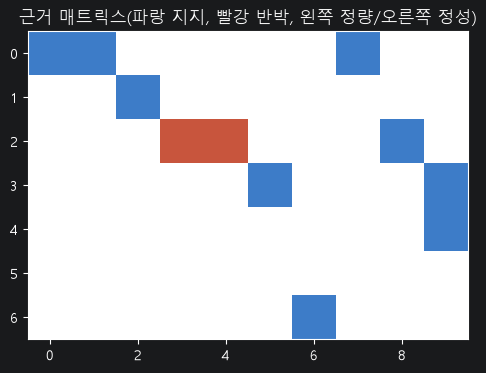

In [27]:
fig, ax = plt.subplots(figsize=(9,4))
ax.imshow(matrix.values, cmap=cmap, vmin=-1, vmax=1)
ax.set_title('근거 매트릭스(파랑 지지, 빨강 반박, 왼쪽 정량/오른쪽 정성)')
plt.show()

In [ ]:
fig, ax = plt.subplots(figsize=(9,4))
ax.imshow(matrix.values, cmap=cmap, vmin=-1, vmax=1)




ax.set_title('근거 매트릭스(파랑 지지, 빨강 반박, 왼쪽 정량/오른쪽 정성)')
plt.show()